# Anatomy of Persuasion · Early OP engagement

**Among branches with similar early comment counts, are branches with an early OP reply more likely to receive a later delta?**

This study scans every discussion in the original training split. Each top-level reply opens a branch. Descendant comments from opening through hour 24 supply the activity and engagement counts. The outcome is the branch's first verified OP delta **after hour 24 and within the following seven days**. An award at hour 24 belongs to the observation period.

The extraction script lives in the matching `op_engagement_study/` folder. It scans the frozen local mirror of PostgreSQL metadata and the v1 text Parquet shards in bulk, then writes the branch table, award evidence, and audit counts to `project/data/processed/op-engagement-study/`. This notebook loads those files and rebuilds them on first use if missing. The plot requires `pandas`, `numpy`, and `matplotlib`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display


REPO = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "team-setup").is_dir() and (path / "pyproject.toml").is_file()
)
STUDY = REPO / "project/notebooks/nested-replies-analysis/op_engagement_study"
DATA = REPO / "project/data/processed/op-engagement-study"
if not all((DATA / name).is_file() for name in ("branches.parquet", "verified_awards.parquet", "audit.json")):
    subprocess.run([sys.executable, str(STUDY / "build_branch_dataset.py")], check=True)

branches = pd.read_parquet(DATA / "branches.parquet")
awards = pd.read_parquet(DATA / "verified_awards.parquet")
audit = json.loads((DATA / "audit.json").read_text())

## Validate the outcome and the observation window

A verified award requires an archived **DeltaBot confirmation → award comment written by the OP → recipient comment** chain. We follow the recipient's parents to its top-level opening. The award comment's creation time and DeltaBot's confirmation time bracket the observable evidence. A comment may have been edited, so we exclude a branch if those timestamps fall on opposite sides of either outcome boundary. We compare reconstructed branches against the paper's published positive openings as an audit. The published labels supply no outcome timestamps.

We exclude confirmed deltas within the first day, uncertain award attribution, and branches with missing ancestry or unusable timing. We use May 8, 2015 UTC as a conservative administrative boundary for training follow-up, and exclude January 2013 from the risk set because the paper documents uncertain DeltaBot coverage there. These bounds cannot guarantee a complete record for every Reddit branch. A negative means **no verified OP award in the fixed window of this archive**.

[Original study, Table 1 and §2](https://www.cs.cornell.edu/~cristian/pdfs/winning_arguments.pdf)

In [2]:
# Show the full-training audit and the reasons branches left the risk set.
display(pd.Series(audit["counts"], name="count").to_frame())
display(pd.Series(audit["exclusions"], name="branches").sort_values(ascending=False).to_frame())
display(branches.head()[[
    "post_id", "branch_id", "branch_created_utc", "comments_24h",
    "op_replies_24h", "op_engaged_24h", "delta_after_24h", "eligible",
]])

# Spot-check the discussion we already traced. Long bot delays can change eligibility.
example_id = "t3_18dj9h"
example = awards.loc[awards["post_id"].eq(example_id)].merge(
    branches[["branch_id", "observation_end_utc", "followup_end_utc", "exclusion_reason"]],
    on="branch_id", validate="many_to_one"
)
for column in ("award_utc", "confirmation_utc", "observation_end_utc", "followup_end_utc"):
    example[column] = pd.to_datetime(example[column], unit="s", utc=True)
display(example[[
    "branch_id", "recipient_comment_id", "award_utc", "confirmation_utc",
    "observation_end_utc", "followup_end_utc", "exclusion_reason",
]])

,count
published_positive_openings,3438
published_positive_openings_with_verified_award,3438
positive_op_labels_without_verified_award,0
confirmed_non_op_awards_ignored,2708
posts_with_unlinked_comments,17
unlinked_comments,25
training_posts,18363
training_comments,1114533
op_or_bot_text_ids_requested,174669
op_or_bot_text_ids_found,174669


,branches
delta_by_24h,5626
beyond_training_followup_boundary,2461
missing_or_invalid_branch_timestamp,1685
not_challenger_opening,1042
uncertain_award_attribution,915
incomplete_parent_path,453
award_and_confirmation_cross_cutoff,258
before_reliable_bot_period,122


,post_id,branch_id,branch_created_utc,comments_24h,op_replies_24h,op_engaged_24h,delta_after_24h,eligible
0,t3_16ra7x,t1_c82eytu,1.358985e+09,1.0,1.0,True,NaN,False
1,t3_16ra7x,t1_c82qhi3,1.359038e+09,0.0,0.0,False,NaN,False
2,t3_16ra7x,t1_c839g1h,1.359098e+09,0.0,0.0,False,NaN,False
3,t3_16ra7x,t1_c83ig3r,1.359142e+09,0.0,0.0,False,NaN,False
4,t3_16ra7x,t1_c8busfv,1.360365e+09,0.0,0.0,False,0.0,True


,branch_id,recipient_comment_id,award_utc,confirmation_utc,observation_end_utc,followup_end_utc,exclusion_reason
0,t1_c8dtv3e,t1_c8fjr4s,2013-02-15 18:40:34+00:00,2013-02-24 12:48:08+00:00,2013-02-13 14:17:45+00:00,2013-02-20 14:17:45+00:00,award_and_confirmation_cross_cutoff
1,t1_c8go2f3,t1_c8go2f3,2013-02-17 18:57:23+00:00,2013-02-24 12:49:54+00:00,2013-02-18 14:39:06+00:00,2013-02-25 14:39:06+00:00,award_and_confirmation_cross_cutoff


## Check overlap before comparing rates

A branch with zero early comments cannot contain an early OP reply. For the figure, retain exact positive comment counts with at least **20 eligible branches in each OP group**. Choose bins from observed support and condense sparse higher counts for readability. This uses only branch counts and OP participation to decide support. The wider bins can still contain different mixes of exact comment counts.

In [3]:
# Count the two participation groups at every exact early comment count.
eligible = branches.loc[branches["eligible"]].copy()
eligible["comments_24h"] = eligible["comments_24h"].astype(int)
eligible["op_engaged_24h"] = eligible["op_engaged_24h"].astype(bool)
eligible["delta_after_24h"] = eligible["delta_after_24h"].astype(int)
exact_counts = (
    eligible.groupby(["comments_24h", "op_engaged_24h"]).size().unstack(fill_value=0)
    .reindex(columns=[False, True], fill_value=0)
)
MIN_PER_GROUP = 20
supported_counts = exact_counts.index[exact_counts.min(axis=1).ge(MIN_PER_GROUP)]
comparison = eligible.loc[eligible["comments_24h"].isin(supported_counts)].copy()
bins = ["1", "2", "3", "4–5", "6–10", "11+"]
comparison["volume_bin"] = pd.cut(
    comparison["comments_24h"], bins=[0, 1, 2, 3, 5, 10, np.inf], labels=bins,
)
if comparison.empty:
    raise ValueError("No exact comment counts have enough branches from both OP groups.")

print(f"Eligible branches: {len(eligible):,}")
print(f"Zero early comments: {int(eligible['comments_24h'].eq(0).sum()):,}")
print(f"Branches on common support: {len(comparison):,} across {len(supported_counts)} exact counts")
display(exact_counts.head(15).rename(columns={False: "OP did not reply", True: "OP replied"}))

Eligible branches: 207,564
Zero early comments: 108,827
Branches on common support: 97,143 across 46 exact counts


op_engaged_24h,OP did not reply,OP replied
comments_24h,,
0,108827,0
1,12864,12640
2,6271,11061
3,3504,7059
4,2460,5451
5,1729,4135
6,1336,3266
7,994,2562
8,844,2053


## Later delta rates on common support

Each dot is the observed share of branches that received a later delta. The 95% intervals resample whole **OP discussions** so that branches under the same post stay together. The table also reports the within-bin percentage-point difference. This is a descriptive association within the archived training discussions.

In [4]:
# Build one count vector per post so the bootstrap preserves dependencies between branches.
keys = ["post_id", "volume_bin", "op_engaged_24h"]
counts = comparison.groupby(keys, observed=True).agg(
    branches=("delta_after_24h", "size"),
    later_deltas=("delta_after_24h", "sum"),
)
shown_bins = [label for label in bins if comparison["volume_bin"].eq(label).any()]
groups = pd.MultiIndex.from_product([shown_bins, [False, True]], names=keys[1:])
branch_matrix = counts["branches"].unstack(keys[1:], fill_value=0).reindex(columns=groups, fill_value=0)
delta_matrix = counts["later_deltas"].unstack(keys[1:], fill_value=0).reindex(columns=groups, fill_value=0)
branch_totals = branch_matrix.sum(axis=0).to_numpy()
delta_totals = delta_matrix.sum(axis=0).to_numpy()
point_rates = delta_totals / branch_totals

# Resample posts rather than individual branches. Each sampled post contributes all its rows.
rng = np.random.default_rng(42)
n_posts = len(branch_matrix)
replicates = []
for _ in range(20):
    weights = rng.multinomial(n_posts, np.full(n_posts, 1 / n_posts), size=50)
    denominators = weights @ branch_matrix.to_numpy()
    numerators = weights @ delta_matrix.to_numpy()
    replicates.append(np.divide(
        numerators, denominators, out=np.full(numerators.shape, np.nan), where=denominators > 0
    ))
boot_rates = np.concatenate(replicates)
lo, hi = np.nanquantile(boot_rates, [0.025, 0.975], axis=0)
rate_summary = pd.DataFrame({
    "branches": branch_totals, "later_deltas": delta_totals,
    "rate_pct": 100 * point_rates, "ci_low_pct": 100 * lo, "ci_high_pct": 100 * hi,
}, index=groups)

# The columns alternate between no early OP reply and an early OP reply.
boot_difference = boot_rates[:, 1::2] - boot_rates[:, ::2]
difference_lo, difference_hi = np.nanquantile(boot_difference, [0.025, 0.975], axis=0)
differences = pd.DataFrame({
    "OP minus no OP (pp)": 100 * (point_rates[1::2] - point_rates[::2]),
    "95% CI lower (pp)": 100 * difference_lo,
    "95% CI upper (pp)": 100 * difference_hi,
}, index=pd.Index(shown_bins, name="volume_bin"))
display(rate_summary.round(3))
display(differences.round(3))

branches  later_deltas  rate_pct  ci_low_pct  ci_high_pct
volume_bin op_engaged_24h                                                           
1          False              12864            17     0.132       0.077        0.203
           True               12640            29     0.229       0.135        0.343
2          False               6271             3     0.048       0.000        0.111
           True               11061            30     0.271       0.173        0.376
3          False               3504             2     0.057       0.000        0.143
           True                7059            29     0.411       0.258        0.574
4–5        False               4189            13     0.310       0.147        0.481
           True                9586            40     0.417       0.288        0.552
6–10       False               4514             5     0.111       0.022        0.204
           True               11785            50     0.424       0.313        0.558
11+        False               3631             7     0.193       0.057        0.339
           True               10039            35     0.349       0.236        0.475

,OP minus no OP (pp),95% CI lower (pp),95% CI upper (pp)
volume_bin,,,
1,0.097,-0.028,0.223
2,0.223,0.115,0.344
3,0.354,0.182,0.545
4–5,0.107,-0.097,0.319
6–10,0.314,0.167,0.473
11+,0.156,-0.031,0.335


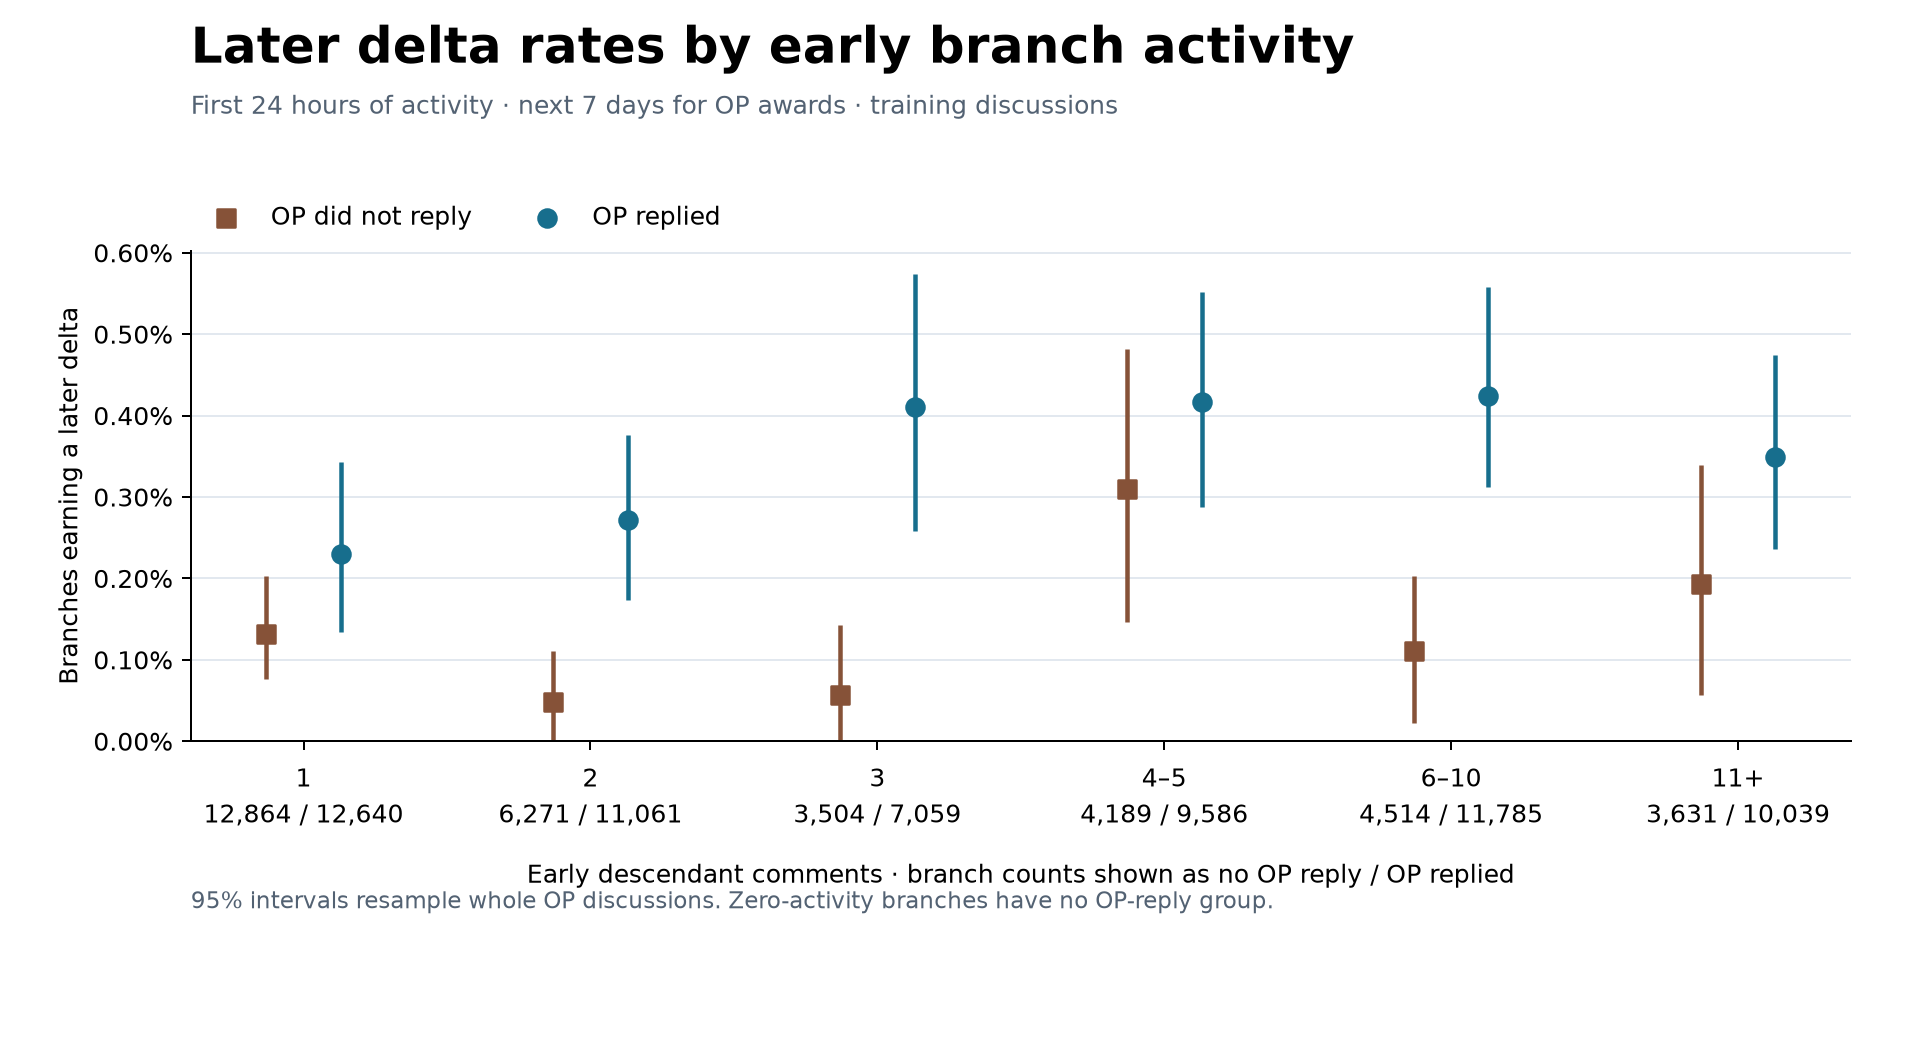

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


fig, ax = plt.subplots(figsize=(10.6, 5.8))
fig.subplots_adjust(left=0.10, right=0.97, bottom=0.29, top=0.76)
fig.text(0.10, 0.94, "Later delta rates by early branch activity", fontsize=20, weight="bold")
fig.text(0.10, 0.891, "First 24 hours of activity · next 7 days for OP awards · training discussions",
         fontsize=10, color="#536273")
positions = np.arange(len(shown_bins))

for engaged, offset, color, marker, label in (
    (False, -0.13, "#865238", "s", "OP did not reply"),
    (True, 0.13, "#176e8d", "o", "OP replied"),
):
    rows = rate_summary.xs(engaged, level="op_engaged_24h")
    # Draw the percentile interval and the observed estimate independently.
    ax.vlines(positions + offset, rows["ci_low_pct"], rows["ci_high_pct"], color=color, lw=1.8)
    ax.scatter(positions + offset, rows["rate_pct"], s=52, c=color, marker=marker, label=label, zorder=3)

labels = []
for label in shown_bins:
    no_op = rate_summary.loc[(label, False), "branches"]
    with_op = rate_summary.loc[(label, True), "branches"]
    labels.append(f"{label}\n{no_op:,} / {with_op:,}")
ax.set_xticks(positions, labels, linespacing=1.5)
ax.set_xlabel("Early descendant comments · branch counts shown as no OP reply / OP replied", labelpad=12)
ax.set_ylabel("Branches earning a later delta")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", color="#e2e8ef")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False, ncols=2, borderaxespad=0)
fig.text(0.10, 0.13, "95% intervals resample whole OP discussions. Zero-activity branches have no OP-reply group.",
         fontsize=9, color="#536273")
fig.savefig(STUDY / "later_delta_rates.png", dpi=180, facecolor="white")
plt.show()